# 06. Error analysis

**Goal.** Understand *why* the chosen model is wrong, not only how often, using the **validation predictions** from notebook 05. The outer
test groups are not used.

The chosen model (notebook 05) is whichever the protocol's rule picked; its predictions, and those of commit count alone for comparison,
are analysed by group, team size, activity and size of the error.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
sys.path.insert(0, str(Path("training").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from common import RESULTS, SEED, SPLITS, environment, group_bootstrap, load, log_run, metrics, paired_diff_bootstrap
from features import FEATURE_SETS, LABEL_SOURCES, add_team_context, feature_matrix, training_set
from final import fit_chosen, make_model, roles_for

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 190)
pd.set_option("display.max_columns", 40)
d = add_team_context(load().set_index("record_id", drop=False))
GOLD = d[d.label_source == "rater"]
choice = json.loads((RESULTS / "model_choice.json").read_text())
print(environment())
print("model chosen in notebook 05:", choice)

{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': '2a23bdaa674b', 'splits_hash': 'b5793a57b501'}
model chosen in notebook 05: {'model': 'Ridge', 'feature_set': '3 features (chosen)', 'reason': 'no forest or boosting model passes protocol conditions 1-3 against Ridge', 'validation_MAE': 0.0774}


In [2]:
pred = pd.read_csv(RESULTS / "comparison_tuned_predictions.csv")
base = pd.read_csv(RESULTS / "baseline_validation_predictions.csv")
name = f"{choice['model']} | {choice['feature_set']}"
m = (pred[pred.name == name].groupby(["outer_test", "inner_val", "record_id", "group"])
     .agg(y=("y", "first"), pred=("pred", "mean"), E_CC=("E_CC", "first")).reset_index())
c = base[base.model == "commits (normalised)"].rename(columns={"pred": "commit_pred", "E_CC": "E_CC_b"})[["outer_test", "inner_val", "record_id", "commit_pred"]]
m = m.merge(c, on=["outer_test", "inner_val", "record_id"])
m["err"] = m.pred - m.y
m["abs_err"] = m.err.abs()
m = m.join(d[["team_id", "team_size", "student_id", "E_LOC_net_capped", "E_FC", "E_CT"]], on="record_id")
print(name, "|", len(m), "validation predictions,", m.record_id.nunique(), "rated records")

Ridge | 3 features (chosen) | 80 validation predictions, 20 rated records


## 1. Residuals

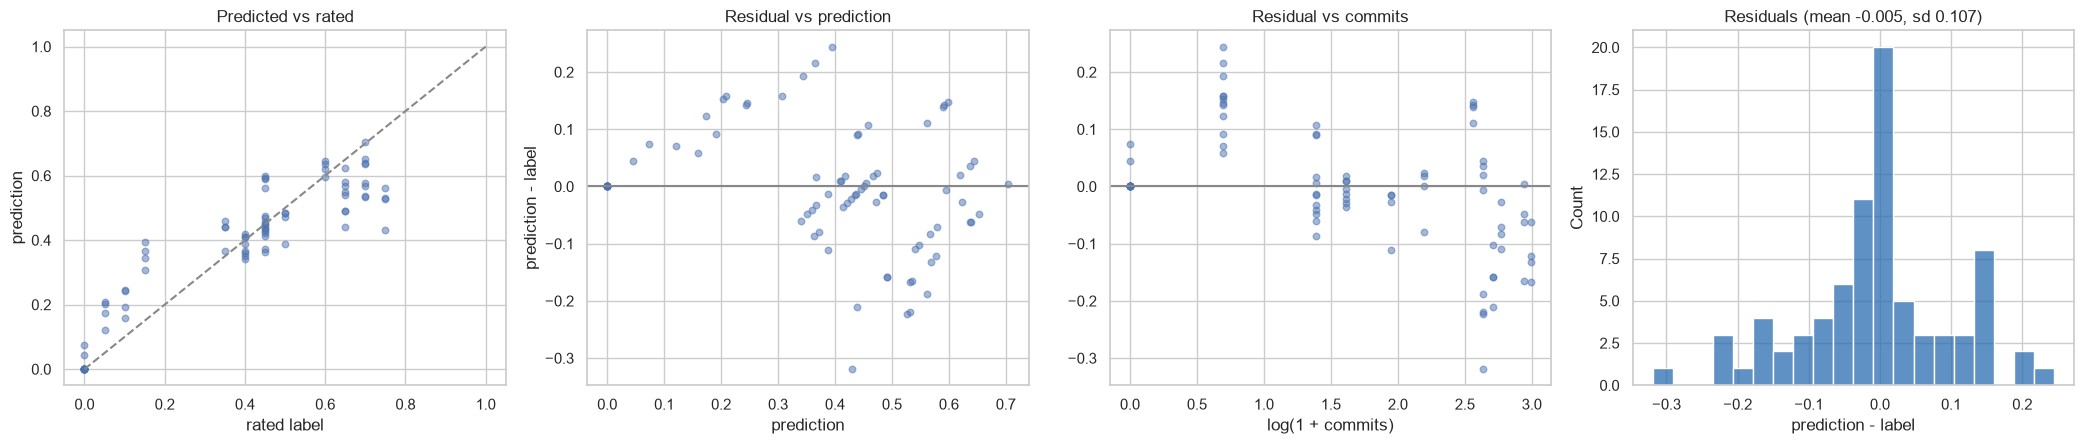

{'MAE': 0.077, 'RMSE': 0.106, 'bias': -0.005, 'pearson': 0.911, 'spearman': 0.879, 'calib_slope': 1.139, 'calib_intercept': -0.049}


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
axes[0].scatter(m.y, m.pred, s=22, alpha=.5); axes[0].plot([0, 1], [0, 1], "--", color="#888")
axes[0].set(title="Predicted vs rated", xlabel="rated label", ylabel="prediction")
axes[1].scatter(m.pred, m.err, s=22, alpha=.5); axes[1].axhline(0, color="#888")
axes[1].set(title="Residual vs prediction", xlabel="prediction", ylabel="prediction - label")
axes[2].scatter(np.log1p(m.E_CC), m.err, s=22, alpha=.5); axes[2].axhline(0, color="#888")
axes[2].set(title="Residual vs commits", xlabel="log(1 + commits)")
sns.histplot(m.err, bins=20, ax=axes[3], color="#2b6cb0")
axes[3].set(title=f"Residuals (mean {m.err.mean():.3f}, sd {m.err.std():.3f})", xlabel="prediction - label")
plt.tight_layout()
plt.show()
mm = metrics(m.y, m.pred)
print({k: round(v, 3) for k, v in mm.items() if k in ("MAE", "RMSE", "bias", "pearson", "spearman", "calib_slope", "calib_intercept")})

## 2. Where does the error concentrate?

In [4]:
def breakdown(by, frame=m):
    t = frame.groupby(by).agg(records=("record_id", "nunique"), MAE=("abs_err", "mean"), bias=("err", "mean"))
    return t.round(3)

m["activity"] = pd.cut(m.E_CC, [-1, 0, 5, 15, 1000], labels=["no commits", "1-5 commits", "6-15 commits", "16+ commits"])
m["label range"] = pd.cut(m.y, [-0.01, 0.1, 0.3, 0.5, 0.8], labels=["0-0.1", "0.1-0.3", "0.3-0.5", "0.5-0.8"])
for by in ["activity", "label range", "team_size", "group"]:
    print(f"--- by {by}")
    print(breakdown(by).to_string())

--- by activity
              records    MAE   bias
activity                           
no commits          3  0.010  0.010
1-5 commits         8  0.078  0.053
6-15 commits        7  0.100 -0.051
16+ commits         2  0.095 -0.094
--- by label range
             records    MAE   bias
label range                       
0-0.1              5  0.053  0.053
0.1-0.3            1  0.203  0.203
0.3-0.5            8  0.049  0.009
0.5-0.8            6  0.114 -0.105
--- by team_size
           records    MAE   bias
team_size                       
3.0              2  0.026  0.003
4.0             16  0.079 -0.018
5.0              2  0.116  0.097
--- by group
       records    MAE   bias
group                       
A            7  0.098 -0.015
B            4  0.091 -0.086
C            4  0.072  0.061
D            3  0.069  0.038
E            2  0.000  0.000


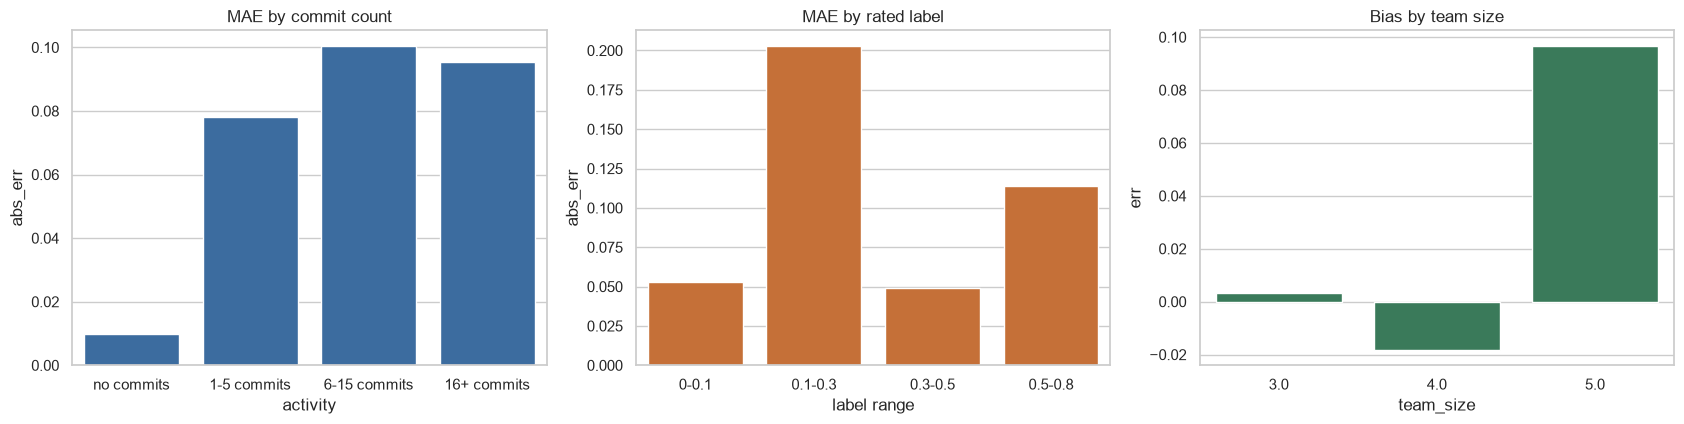

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
sns.barplot(data=m, x="activity", y="abs_err", ax=axes[0], color="#2b6cb0", errorbar=None); axes[0].set(title="MAE by commit count")
sns.barplot(data=m, x="label range", y="abs_err", ax=axes[1], color="#dd6b20", errorbar=None); axes[1].set(title="MAE by rated label")
sns.barplot(data=m, x="team_size", y="err", ax=axes[2], color="#2f855a", errorbar=None); axes[2].set(title="Bias by team size")
plt.tight_layout()
plt.show()

## 3. The largest errors

In [6]:
worst = (m.groupby("record_id").agg(rated=("y", "first"), model=("pred", "mean"), commit_only=("commit_pred", "mean"), commits=("E_CC", "first"),
                                    lines=("E_LOC_net_capped", "first"), files=("E_FC", "first"), tasks_done=("E_CT", "first"), team_size=("team_size", "first"),
                                    err=("abs_err", "mean")).sort_values("err", ascending=False))
worst.head(8).round(3)

,rated,model,commit_only,commits,lines,files,tasks_done,team_size,err
record_id,,,,,,,,,
T13-S2-STU-006,0.75,0.513,0.589,13,1594,25,4,4.0,0.237
T03-S2-STU-011,0.15,0.353,0.155,1,800,21,0,5.0,0.203
T09-S1-STU-007,0.65,0.493,0.624,14,862,12,3,4.0,0.157
T08-S1-STU-008,0.45,0.585,0.575,12,794,48,2,4.0,0.135
T04-S3-STU-010,0.05,0.177,0.155,1,12,2,0,4.0,0.127
T09-S1-STU-001,0.70,0.579,0.691,19,1561,55,3,4.0,0.121
T04-S2-STU-027,0.10,0.210,0.155,1,36,4,1,4.0,0.110
T01-S2-STU-021,0.35,0.426,0.309,3,828,39,0,4.0,0.076


## 4. What the model relies on

Drop-one-feature test: refit without each of the three features in every validation combination and see how much the error rises.

In [7]:
splits = pd.read_csv(SPLITS)
combos = [(t, v, g[["record_id", "role"]]) for (t, v), g in splits.groupby(["outer_test", "inner_val"])]
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

fs = "3 features (chosen)"
names = ["commits", "lines (capped)", "files"]
out = {}
for drop in [None, 0, 1, 2]:
    errs = []
    for test, val, roles in combos:
        X, y, w, ids = training_set(d, roles, lambda f: feature_matrix(f, fs, "linear"), "rated only", 1.0, real_only=False)
        v = d.loc[[i for i in roles[roles.role == "val"].record_id if i in GOLD.index]]
        Xv = feature_matrix(v, fs, "linear")
        keep = [i for i in range(3) if i != drop]
        mdl = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X[:, keep], y, ridge__sample_weight=w)
        errs += list(np.abs(np.clip(mdl.predict(Xv[:, keep]), 0, 1) - v.rater_effort.to_numpy()))
    out["all three" if drop is None else f"without {names[drop]}"] = np.mean(errs)
imp = pd.Series(out, name="validation MAE (Ridge, alpha 1, rated labels)")
imp.round(4).to_frame()

,"validation MAE (Ridge, alpha 1, rated labels)"
all three,0.0590
without commits,0.0926
without lines (capped),0.0698
without files,0.0568


In [8]:
# coefficients of the Ridge model on the three features, fitted on all rated records (for explanation only)
r = GOLD
X = feature_matrix(r, fs, "linear")
mdl = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X, r.rater_effort.to_numpy())
coef = pd.Series(mdl.named_steps["ridge"].coef_, index=names, name="effect on the score of +1 standard deviation (log scale)")
coef.round(3).to_frame()

,effect on the score of +1 standard deviation (log scale)
commits,0.179
lines (capped),0.068
files,-0.007


## 5. Reading the results

**The model analysed:** Ridge on commits, lines and files, the model the protocol's rule chose (validation MAE 0.077, bias -0.005, calibration slope 1.14).

**Where the error is**

- **Largest at the top of the label range.** Records rated 0.5-0.8 have MAE 0.114 and bias **-0.105**: the model under-predicts strong students
  (e.g. rated 0.75, predicted 0.51, with 13 commits and 4 tasks done). Records rated 0.3-0.5 are fitted well (MAE 0.049).
- **Slightly over-predicts weak students.** Records rated 0-0.3 have bias +0.05 to +0.20 (one record rated 0.15 with 1 commit and 800 lines is
  predicted 0.35).
- **No-commit students are essentially perfect** (MAE 0.010; the three rated inactive records are labelled 0).
- **By activity,** error grows with commits: 0.078 for 1-5 commits, 0.100 for 6-15, 0.095 for 16+, with the bias turning from +0.05 to -0.09
  (the model flattens: too high for the weakest, too low for the strongest). The 16+ group has only two rated records.
- **Team size 5** shows +0.097 bias (two records), team size 3 almost none. Too few records to conclude.
- **By group,** MAE ranges 0.069-0.098 (group E has two records, both exact). No single group drives the result.

**What the model relies on (drop-one refit, validation MAE 0.059 with all three)**

| Removed | MAE | Change |
|---|---|---|
| commits | 0.093 | +0.034, the dominant feature |
| lines (capped) | 0.070 | +0.011, useful |
| files | 0.057 | -0.002, **adds nothing** |

Fitted on all rated records, the effect of +1 standard deviation (on the log scale) is +0.179 for commits, +0.068 for lines and -0.007 for files.
The model is a commit-and-lines score; files contribute nothing.

**What it means.** The flattening toward the middle is the classic signature of fitting 9-15 labels with shrinkage, and of labels that stop at
0.75. It cannot be fixed by tuning; it needs labels at both ends. The error pattern also says that the standard deviation of the predictions
is smaller than that of the labels, so a calibration slope above 1 (1.14) is to be expected.